# Seminar 6. Second-Order Methods Part Two

Checks and NumPy experiments for Gauss–Newton, Levenberg–Marquardt, trust region and L-BFGS.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

SEED = 42
TOPIC = "Second-Order Methods Part Two"
SEMINAR = "06"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    if not rows:
        return
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-9):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    typed = float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          max(tol, 1e-4 * max(1, abs(float(computed)))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    # When the tolerance is a sizeable fraction of the value, the 1% rejection test is uninformative.
    if abs(value) > 1e-6 and tol < 0.005 * abs(value):
        check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
              not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")


numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/06. Second-Order Methods Part Two.ipynb
data leaves: 253 public, 50 students


## 2. NumPy methods

Small implementations the problems reuse: Gauss–Newton, Levenberg–Marquardt, the dogleg for a positive definite Hessian, the BFGS inverse update and the two-loop recursion.

In [2]:
def lm_step(theta, r_func, j_func, lam):
    """One Levenberg-Marquardt trial step: (J^T J + lam I) p = -J^T r, with the ratio rho."""
    Jk, rk = j_func(theta), r_func(theta)
    g = Jk.T @ rk
    B = Jk.T @ Jk
    p = np.linalg.solve(B + lam * np.eye(len(theta)), -g)
    model_drop = -(g @ p + 0.5 * p @ B @ p)
    actual = 0.5 * rk @ rk - 0.5 * r_func(theta + p) @ r_func(theta + p)
    rho = actual / model_drop if model_drop > 0 else -1.0
    return p, rho, model_drop, g, B


def bfgs_inverse_update(G, s, y):
    """Inverse BFGS update: G_{+} = V G V^T + rho s s^T, V = I - rho s y^T, rho = 1/(y^T s)."""
    rho = 1.0 / (y @ s)
    V = np.eye(len(s)) - rho * np.outer(s, y)
    return V @ G @ V.T + rho * np.outer(s, s)


def two_loop(g, pairs, gamma):
    """The L-BFGS two-loop recursion: direction -Gg without forming G."""
    q = g.copy()
    alphas = []
    for s, yv in reversed(pairs):
        a = (s @ q) / (yv @ s)
        alphas.append(a)
        q = q - a * yv
    r = gamma * q
    for (s, yv), a in zip(pairs, reversed(alphas)):
        b = (yv @ r) / (yv @ s)
        r = r + s * (a - b)
    return -r


## 3. The problems

### A1. Gauss–Newton on an exponential fit

$f_\theta(t)=a\,e^{bt}$ at four points; two Gauss–Newton steps from $\theta_0=(1,1)$.

In [3]:
pts = np.array(PUB["A1"]["params"]["pts"])
t_a, y_a = pts[:, 0], pts[:, 1]


def r_a(theta):
    a, b = theta
    return a * np.exp(b * t_a) - y_a


def J_a(theta):
    a, b = theta
    e = np.exp(b * t_a)
    return np.column_stack([e, a * t_a * e])


def f_a(theta):
    rk = r_a(theta)
    return 0.5 * rk @ rk


theta0 = np.array(PUB["A1"]["params"]["theta0"], float)
pred0 = theta0[0] * np.exp(theta0[1] * t_a)
r0 = pred0 - y_a
J0 = J_a(theta0)
JtJ0 = J0.T @ J0
Jtr0 = J0.T @ r0
p0 = np.linalg.solve(JtJ0, -Jtr0)
theta1 = theta0 + p0
pred1 = theta1[0] * np.exp(theta1[1] * t_a)
r1 = pred1 - y_a
J1 = J_a(theta1)
p1 = np.linalg.solve(J1.T @ J1, -J1.T @ r1)
theta2 = theta1 + p1
f0_a1, f1_a1, f2_a1 = f_a(theta0), f_a(theta1), f_a(theta2)

expect("A1.params", {"pts": pts.tolist(), "theta0": theta0.tolist()})
expect("A1.pred0", pred0)
expect("A1.r0", r0)
expect("A1.J0", J0)
expect("A1.JtJ0", JtJ0)
expect("A1.Jtr0", Jtr0)
expect("A1.p0", p0)
expect("A1.theta1", theta1)
expect("A1.pred1", pred1)
expect("A1.r1", r1)
expect("A1.J1", J1)
expect("A1.p1", p1)
expect("A1.theta2", theta2)
expect("A1.f0", f0_a1)
expect("A1.f1", f1_a1)
expect("A1.f2", f2_a1)

# Sanity: the Jacobian formulas come from the sympy derivative of the residual.
a_s, b_s, t_s, y_s = sp.symbols("a b t y")
r_sym = a_s * sp.exp(b_s * t_s) - y_s
check("A1: sympy derivative in a", sp.simplify(sp.diff(r_sym, a_s) - sp.exp(b_s * t_s)), 0)
check("A1: sympy derivative in b", sp.simplify(sp.diff(r_sym, b_s) - a_s * t_s * sp.exp(b_s * t_s)), 0)

expect_answer("A1.a1", theta1[0])
expect_answer("A1.b1", theta1[1])
expect_answer("A1.f2", f2_a1)
section("A1")


A1: A1.params                                    {pts: [[0, 2], [1, 3.3], [2, 5.4], [3...  ok
A1: A1.pred0                                     [1, 2.718281828, 7.389056099, 20.0855...  ok
A1: A1.r0                                        [-1, -0.5817181715, 1.989056099, 11.0...  ok
A1: A1.J0                                        [[1, 0], [2.718281828, 2.718281828], ...  ok
A1: A1.JtJ0                                      [[466.4159996, 1326.871737], [1326.87...  ok
A1: A1.Jtr0                                      [234.7749343, 695.7901038]                ok
A1: A1.p0                                        [0.4653614857, -0.3405204621]             ok
A1: A1.theta1                                    [1.465361486, 0.6594795379]               ok
A1: A1.pred1                                     [1.465361486, 2.833694955, 5.47975852...  ok
A1: A1.r1                                        [-0.5346385143, -0.466305045, 0.07975...  ok
A1: A1.J1                                        [[1, 0], [1

### A2. Levenberg–Marquardt rescues a wild start

Same residual as A1; start at $\theta_0=(10,1.5)$ with $\lambda_0=1$ and the standard adaptive rule, three accepted steps.

In [4]:
theta = np.array(PUB["A2"]["params"]["theta0"], float)
lam0 = float(PUB["A2"]["params"]["lam0"])
rho_good = float(PUB["A2"]["params"]["rhoGood"])
shrink = float(PUB["A2"]["params"]["shrink"])
grow = float(PUB["A2"]["params"]["grow"])

expect("A2.params", {"theta0": theta.tolist(), "lam0": lam0,
                     "rhoGood": rho_good, "shrink": shrink, "grow": grow})

lam = lam0
accepted = []
rejects_a2 = 0
history_a2 = []
for _ in range(60):
    if len(accepted) == 3:
        break
    p, rho, drop, g, B = lm_step(theta, r_a, J_a, lam)
    history_a2.append({"theta": theta.copy(), "lam": lam, "p": p.copy(), "rho": rho})
    if rho >= rho_good:
        theta = theta + p
        accepted.append(theta.copy())
        lam = lam / shrink
    else:
        lam = lam * grow
        rejects_a2 += 1

accepted1 = accepted[0]
accepted3 = accepted[2]

expect("A2.accepted1", accepted1)
expect("A2.accepted3", accepted3)
expect("A2.rejects", rejects_a2)
expect("A2.f0", f_a(np.array(PUB["A2"]["params"]["theta0"], float)))
expect("A2.f1", f_a(accepted[0]))
expect("A2.f3", f_a(accepted[2]))

expect_answer("A2.a1", accepted1[0])
expect_answer("A2.b3", accepted3[1])
expect_answer("A2.rejects", rejects_a2)
section("A2")


A2: A2.params                                    {theta0: [10, 1.5], lam0: 1, rhoGood:...  ok
A2: A2.accepted1                                 [0.8765387296, 1.474020567]               ok
A2: A2.accepted3                                 [1.078537294, 0.8462746042]               ok
A2: A2.rejects                                   0                                         ok
A2: A2.f0                                        417088.3813                               ok
A2: A2.f1                                        2111.973325                               ok
A2: A2.f3                                        11.69435797                               ok
A2: answer a1 is a number spec                   [[tol, type, value], number]              ok
A2: answer a1 equals the computed value          3.87295547e-05                            ok
A2: answer a1: the tolerance accepts 0.8765      True                                      ok
A2: answer a1: the tolerance rejects a 1% error  True       

### B1. Dogleg on a stretched quadratic

$f(x,y)=\tfrac12(x^2+10y^2)$ at $x_0=(2,1)$, $\Delta=2$.

In [5]:
c = int(PUB["B1"]["params"]["c"])
x0_b1 = np.array(PUB["B1"]["params"]["x0"], float)
delta_b1 = float(PUB["B1"]["params"]["delta"])

B_b1 = np.diag([1.0, float(c)])
g_b1 = B_b1 @ x0_b1
pN = -np.linalg.solve(B_b1, g_b1)
pNnorm = float(np.linalg.norm(pN))
alpha_star = float((g_b1 @ g_b1) / (g_b1 @ B_b1 @ g_b1))
pC = -alpha_star * g_b1
pCnorm = float(np.linalg.norm(pC))
# positive root of ||pC + tau * (pN - pC)|| = delta
d = pN - pC
qa = d @ d
qb = 2 * pC @ d
qc = pC @ pC - delta_b1 ** 2
tau_b1 = (-qb + math.sqrt(qb * qb - 4 * qa * qc)) / (2 * qa)
p_b1 = pC + tau_b1 * d
pnorm = float(np.linalg.norm(p_b1))


def f_b1(x):
    return 0.5 * (x[0] ** 2 + c * x[1] ** 2)


f0_b1 = float(f_b1(x0_b1))
fnew_b1 = float(f_b1(x0_b1 + p_b1))
model_drop_b1 = float(-(g_b1 @ p_b1 + 0.5 * p_b1 @ B_b1 @ p_b1))
rho_b1 = float((f0_b1 - fnew_b1) / model_drop_b1)
delta_next = 2 * delta_b1

expect("B1.params", {"c": c, "x0": x0_b1.tolist(), "delta": delta_b1})
expect("B1.diagB", [1, c])
expect("B1.g", g_b1)
expect("B1.pN", pN)
expect("B1.pNnorm", pNnorm)
expect("B1.alphaStar", alpha_star)
expect("B1.pC", pC)
expect("B1.pCnorm", pCnorm)
expect("B1.tau", tau_b1)
expect("B1.p", p_b1)
expect("B1.pnorm", pnorm)
expect("B1.f0", f0_b1)
expect("B1.fnew", fnew_b1)
expect("B1.modelDrop", model_drop_b1)
expect("B1.rho", rho_b1)
expect("B1.deltaNext", delta_next)

check("B1: the dogleg step hits the boundary", abs(pnorm - delta_b1), 0, 1e-12)
check("B1: rho above 3/4", rho_b1 > 0.75, True)

expect_answer("B1.pc2", pC[1])
expect_answer("B1.p1", p_b1[0])
expect_answer("B1.fnew", fnew_b1)
section("B1")


B1: B1.params                                     {c: 10, x0: [2, 1], delta: 2}             ok
B1: B1.diagB                                      [1, 10]                                   ok
B1: B1.g                                          [2, 10]                                   ok
B1: B1.pN                                         [-2, -1]                                  ok
B1: B1.pNnorm                                     2.236067977                               ok
B1: B1.alphaStar                                  0.1035856574                              ok
B1: B1.pC                                         [-0.2071713147, -1.035856574]             ok
B1: B1.pCnorm                                     1.056370577                               ok
B1: B1.tau                                        0.8487915679                              ok
B1: B1.p                                          [-1.728909185, -1.005421816]              ok
B1: B1.pnorm                                      

### B2. One-dimensional trust region on a quartic

$f(x)=-x+\tfrac14 x^4$ at $x_0=0.5$, $\Delta_0=2$, $\rho_\text{bad}=1/4$, halve $\Delta$ on a rejection.

In [6]:
x0_b2 = float(PUB["B2"]["params"]["x0"])
delta0_b2 = float(PUB["B2"]["params"]["delta0"])
rho_bad = float(PUB["B2"]["params"]["rhoBad"])
shrink_b2 = float(PUB["B2"]["params"]["shrink"])


def f_b2(x):
    return -x + 0.25 * x ** 4


def fp_b2(x):
    return -1 + x ** 3


def fpp_b2(x):
    return 3 * x ** 2


g0_b2 = fp_b2(x0_b2)
B0_b2 = fpp_b2(x0_b2)
pstar = -g0_b2 / B0_b2

delta = delta0_b2
rejects_b2 = 0
accepted_b2 = None
for _ in range(10):
    # Trust-region step in one dimension: shrink the Newton step to the trust radius.
    p_b2 = min(delta, abs(pstar)) * (1.0 if -g0_b2 > 0 else -1.0)
    model_drop = -(g0_b2 * p_b2 + 0.5 * B0_b2 * p_b2 ** 2)
    actual = f_b2(x0_b2) - f_b2(x0_b2 + p_b2)
    rho = actual / model_drop if model_drop > 0 else -1.0
    if rho < rho_bad:
        delta = delta / shrink_b2
        rejects_b2 += 1
        continue
    accepted_b2 = {"delta": delta, "p": p_b2, "x1": x0_b2 + p_b2,
                   "f0": f_b2(x0_b2), "f1": f_b2(x0_b2 + p_b2), "rejects": rejects_b2}
    break

expect("B2.params", {"x0": x0_b2, "delta0": delta0_b2, "rhoBad": rho_bad, "shrink": shrink_b2})
expect("B2.g0", g0_b2)
expect("B2.B0", B0_b2)
expect("B2.pstar", pstar)
expect("B2.deltaFinal", accepted_b2["delta"])
expect("B2.p", accepted_b2["p"])
expect("B2.x1", accepted_b2["x1"])
expect("B2.f0", accepted_b2["f0"])
expect("B2.f1", accepted_b2["f1"])
expect("B2.rejects", accepted_b2["rejects"])

x_sym = sp.symbols("x")
f_sym_b2 = -x_sym + x_sym ** 4 / 4
check("B2: symbolic f(1) matches", float(f_sym_b2.subs(x_sym, 1)), -0.75)

expect_answer("B2.delta", accepted_b2["delta"])
expect_answer("B2.x1", accepted_b2["x1"])
expect_answer("B2.rejects", accepted_b2["rejects"])
section("B2")


B2: B2.params                                       {x0: 0.5, delta0: 2, rhoBad: 0.25, sh...  ok
B2: B2.g0                                           -0.875                                    ok
B2: B2.B0                                           0.75                                      ok
B2: B2.pstar                                        1.166666667                               ok
B2: B2.deltaFinal                                   0.5                                       ok
B2: B2.p                                            0.5                                       ok
B2: B2.x1                                           1                                         ok
B2: B2.f0                                           -0.484375                                 ok
B2: B2.f1                                           -0.75                                     ok
B2: B2.rejects                                      2                                         ok
B2: symbolic f(1) matches     

### C1. BFGS by hand on a quadratic

$f(x)=\tfrac12 x^\top Qx$ with $Q=\operatorname{diag}(1,4)$, $x_0=(2,2)$, $G_0=I$, exact line searches.

In [7]:
Q_c1 = np.array(PUB["C1"]["params"]["Q"], dtype=float)
x0_c1 = np.array(PUB["C1"]["params"]["x0"], float)

G0_c1 = np.eye(2)
g0_c1 = Q_c1 @ x0_c1
p0_c1 = -G0_c1 @ g0_c1
alpha0 = -(g0_c1 @ p0_c1) / (p0_c1 @ Q_c1 @ p0_c1)
s_c1 = alpha0 * p0_c1
x1_c1 = x0_c1 + s_c1
g1_c1 = Q_c1 @ x1_c1
y_c1 = g1_c1 - g0_c1
ys = float(y_c1 @ s_c1)
rho_c1 = 1.0 / ys
G1 = bfgs_inverse_update(G0_c1, s_c1, y_c1)
G1y = G1 @ y_c1
eig = np.linalg.eigvalsh(G1)
p1_c1 = -G1 @ g1_c1
slope1 = float(g1_c1 @ p1_c1)
alpha1 = -(g1_c1 @ p1_c1) / (p1_c1 @ Q_c1 @ p1_c1)
x2_c1 = x1_c1 + alpha1 * p1_c1
B1_mat = np.linalg.inv(G1)

expect("C1.params", {"Q": Q_c1.tolist(), "x0": x0_c1.tolist()})
expect("C1.g0", g0_c1)
expect("C1.p0", p0_c1)
expect("C1.alpha0", alpha0)
expect("C1.s", s_c1)
expect("C1.x1", x1_c1)
expect("C1.g1", g1_c1)
expect("C1.y", y_c1)
expect("C1.ys", ys)
expect("C1.rho", rho_c1)
expect("C1.G1", G1)
expect("C1.G1y", G1y)
expect("C1.eig", eig)
expect("C1.p1", p1_c1)
expect("C1.slope1", slope1)
expect("C1.alpha1", alpha1)
expect("C1.x2", x2_c1)
expect("C1.B1", B1_mat)

check("C1: secant G y = s", G1y, s_c1, 1e-12)
check("C1: G1 symmetric", G1, G1.T, 1e-14)
check("C1: eigenvalues positive", bool(eig[0] > 0 and eig[1] > 0), True)
check("C1: B1 agrees with Q along s", B1_mat @ s_c1, Q_c1 @ s_c1, 1e-10)
check("C1: x2 is the minimizer", x2_c1, [0, 0], 1e-12)

expect_answer("C1.g11", G1[0, 0])
expect_answer("C1.alpha1", alpha1)
expect_answer("C1.x2", x2_c1[0])
section("C1")


C1: C1.params                                        {Q: [[1, 0], [0, 4]], x0: [2, 2]}         ok
C1: C1.g0                                            [2, 8]                                    ok
C1: C1.p0                                            [-2, -8]                                  ok
C1: C1.alpha0                                        0.2615384615                              ok
C1: C1.s                                             [-0.5230769231, -2.092307692]             ok
C1: C1.x1                                            [1.476923077, -0.09230769231]             ok
C1: C1.g1                                            [1.476923077, -0.3692307692]              ok
C1: C1.y                                             [-0.5230769231, -8.369230769]             ok
C1: C1.ys                                            17.78461538                               ok
C1: C1.rho                                           0.0562283737                              ok
C1: C1.G1           

### C2. L-BFGS two-loop recursion by hand

Same quadratic as C1; keep the last $m=2$ pairs, take two steps, apply the two-loop recursion.

In [8]:
m_c2 = int(PUB["C2"]["params"]["m"])
x0_c2 = np.array(PUB["C2"]["params"]["x0"], float)

g_c2_0 = Q_c1 @ x0_c2
p_c2_0 = -g_c2_0
alpha_c2_0 = -(g_c2_0 @ p_c2_0) / (p_c2_0 @ Q_c1 @ p_c2_0)
s0 = alpha_c2_0 * p_c2_0
x1_c2 = x0_c2 + s0
g_c2_1 = Q_c1 @ x1_c2
y0 = g_c2_1 - g_c2_0
gamma1 = (s0 @ y0) / (y0 @ y0)
pairs = [(s0, y0)]
p_c2_1 = two_loop(g_c2_1, pairs, gamma1)
alpha_c2_1 = -(g_c2_1 @ p_c2_1) / (p_c2_1 @ Q_c1 @ p_c2_1)
x2_c2 = x1_c2 + alpha_c2_1 * p_c2_1

expect("C2.params", {"m": m_c2, "x0": x0_c2.tolist()})
expect("C2.gamma1", gamma1)
expect("C2.p1", p_c2_1)
expect("C2.alpha1", alpha_c2_1)
expect("C2.x2", x2_c2)

check("C2: step 0 matches C1", s0, s_c1, 1e-12)
G1_check = bfgs_inverse_update(gamma1 * np.eye(2), s0, y0)
p_dense = -G1_check @ g_c2_1
check("C2: two-loop matches dense BFGS from gamma I kernel", p_c2_1, p_dense, 1e-12)
check("C2: x2 reaches the minimizer to machine precision", np.linalg.norm(x2_c2), 0, 1e-12)

expect_answer("C2.gamma", gamma1)
expect_answer("C2.p1", p_c2_1[0])
expect_answer("C2.x2", x2_c2[0])
section("C2")


C2: C2.params                                        {m: 2, x0: [2, 2]}                        ok
C2: C2.gamma1                                        0.2529182879                              ok
C2: C2.p1                                            [-0.3907812032, 0.0244238252]             ok
C2: C2.alpha1                                        3.779411765                               ok
C2: C2.x2                                            [0, 2.359223927e-16]                      ok
C2: step 0 matches C1                                [-0.5230769231, -2.092307692]             ok
C2: two-loop matches dense BFGS from gamma I kernel  [-0.3907812032, 0.0244238252]             ok
C2: x2 reaches the minimizer to machine precision    2.359223927e-16                           ok
C2: answer gamma is a number spec                    [[tol, type, value], number]              ok
C2: answer gamma equals the computed value           1.828793774e-05                           ok
C2: answer gamma: th

## 4. Exit ticket and block D demo numbers

In [9]:
exit_data = PUB["exit"]
expect("exit.residual", "0")
expect("exit.delta", int(exit_data["delta"]))
expect("exit.rho", float(exit_data["rho"]))
expect("exit.memory", int(exit_data["memory"]))
expect("exit.n", int(exit_data["n"]))
expect("exit.store", int(exit_data["store"]))
expect("exit.cost", int(exit_data["cost"]))

check("exit: store 2 m n", 2 * exit_data["memory"] * exit_data["n"], exit_data["store"])
check("exit: cost 4 m n", 4 * exit_data["memory"] * exit_data["n"], exit_data["cost"])

# Gauss-Newton on f_theta(t) = theta^2 fit to y = -1: step is -(theta^2 + 1) / (2 theta).
# From theta0 = 1/2 it jumps to -3/4; the cycle is a classic example of a large residual.
demo = PUB["demo"]
gnStart = float(demo["gnStart"])
gnStep1 = gnStart - (gnStart ** 2 + 1) / (2 * gnStart)
expect("demo.gnStart", gnStart)
expect("demo.gnStep1", gnStep1)

# Trust-region demo: delta_0 shrunk by four five times goes from 2 to 2/4^5 = 1/512.
tr = demo["tr"]
start_tr = float(tr["start"])
k_tr = int(tr["k"])
shrink_tr = int(tr["shrink"])
after = start_tr / shrink_tr ** k_tr
expect("demo.tr", {"start": start_tr, "after": after, "k": k_tr, "shrink": shrink_tr})

# L-BFGS demo numbers for the kappa = 100 quadratic: they illustrate memory versus iterations.
lbfgs_demo = demo["lbfgs"]
expect("demo.lbfgs", {"kappa": int(lbfgs_demo["kappa"]),
                      "memory": int(lbfgs_demo["memory"]),
                      "steps": {"bfgs": int(lbfgs_demo["steps"]["bfgs"]),
                                "m2": int(lbfgs_demo["steps"]["m2"]),
                                "m10": int(lbfgs_demo["steps"]["m10"])}})
section("exit")


exit: exit.residual  0                                         ok
exit: exit.delta     1                                         ok
exit: exit.rho       0.9                                       ok
exit: exit.memory    5                                         ok
exit: exit.n         1000                                      ok
exit: exit.store     10000                                     ok
exit: exit.cost      20000                                     ok
exit: store 2 m n    10000                                     ok
exit: cost 4 m n     20000                                     ok


## 5. Release and timeline

Start at 10:50 Moscow time; add every planned length and check against config.js.

In [10]:
PLAN = {
    "0": [("recap", 7)],
    "A": [("recap", 3), ("P1", 7), ("P2", 8), ("review", 3)],
    "B": [("recap", 3), ("P1", 7), ("P2", 8), ("review", 3)],
    "C": [("recap", 3), ("P1", 7), ("P2", 8), ("review", 3)],
    "D": [("D1", Fr(5, 2)), ("D2", Fr(5, 2)), ("D3", Fr(5, 2)), ("D4", Fr(5, 2))],
    "E": [("summary", 3), ("exit", 3), ("home", 2)],
}


def mmss(minutes):
    seconds = int(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"


def clock_str(minutes):
    minute = 10 * 60 + 50 + int(minutes)
    return f"{minute // 60}:{minute % 60:02d}"


timeline = {"blocks": list(PLAN), "sec": {}, "start": {}, "clock": {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]["total"] = mmss(total)
    timeline["sec"][block] = {key: int(m * 60) for key, m in parts}
    timeline["start"][block] = mmss(elapsed)
    timeline["clock"][block] = clock_str(elapsed)
    elapsed += total

timeline["buffer"] = mmss(5)
timeline["sec"]["buffer"] = 300
timeline["start"]["buffer"] = mmss(elapsed)
timeline["clock"]["buffer"] = clock_str(elapsed)
timeline["total"] = mmss(elapsed + 5)
timeline["clock"]["end"] = clock_str(elapsed + 5)
expect("timeline", timeline)
check("timeline: total with buffer", elapsed + 5, 93)

day = date(2026, 10, 19)
release = datetime.combine(day, time(12, 30), timezone(timedelta(hours=3)))
expect("release.iso", release.isoformat())
expect("release.day", f"{day.day} {day.strftime('%B')}")
expect("release.dayRu", f"{day.day} октября")
check("timeline: release is on Monday", day.weekday(), 0)
check("timeline: config matches the release",
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / "js/config.js").read_text()), [release.isoformat()])
section("timeline")

all_leaves = [(name, p) for name, data in [("public", PUB), ("students", STU)]
              for key, value in data.items() for p in leaves(value, key)]
check("coverage: every data leaf has an independent calculation", sorted(set(all_leaves) - COVERED), [])
print(f"{len(COVERED)} data leaves checked")


timeline: timeline                    {blocks: [0, A, B, C, D, E], sec: {0:...  ok
timeline: total with buffer           93                                        ok
timeline: release.iso                 2026-10-19T12:30:00+03:00                 ok
timeline: release.day                 19 October                                ok
timeline: release.dayRu               19 октября                                ok
timeline: release is on Monday        0                                         ok
timeline: config matches the release  [2026-10-19T12:30:00+03:00]               ok
303 data leaves checked


## 6. Figures

One figure for block D: Gauss–Newton oscillates on a one-point fit while full Newton converges.

In [11]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar06",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a public figure."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)


### fig_gn_blow: Gauss–Newton oscillation versus Newton

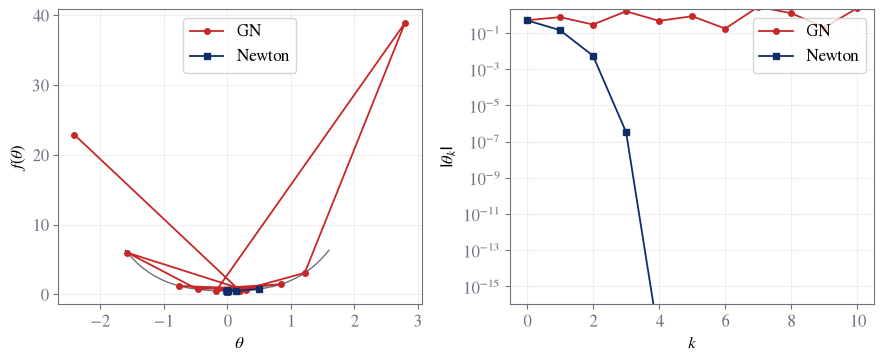

In [12]:
# Gauss-Newton on the one-point fit y = -1 with f_theta(t) = theta^2.
# r(theta) = theta^2 + 1, J = 2 theta, step_GN = -(theta^2 + 1)/(2 theta).
# True Hessian: f'' = 4 theta^2 + 2 (theta^2 + 1), always positive, so full Newton converges.
def gn_iter(theta0, steps):
    th = float(theta0)
    out = [th]
    for _ in range(steps):
        th = th - (th ** 2 + 1) / (2 * th)
        out.append(th)
    return np.array(out)


def newton_iter(theta0, steps):
    # f(theta) = (theta^2 + 1)^2 / 2
    # f'(theta) = 2 theta (theta^2 + 1)
    # f''(theta) = 2 (3 theta^2 + 1)
    th = float(theta0)
    out = [th]
    for _ in range(steps):
        th = th - 2 * th * (th ** 2 + 1) / (2 * (3 * th ** 2 + 1))
        out.append(th)
    return np.array(out)


gn_path = gn_iter(float(PUB["demo"]["gnStart"]), 10)
nt_path = newton_iter(float(PUB["demo"]["gnStart"]), 10)
check("figures: Gauss-Newton step from 1/2 goes to -3/4", gn_path[1], float(PUB["demo"]["gnStep1"]), 1e-14)
check("figures: Newton converges to the minimizer theta* = 0", abs(nt_path[-1]) < 1e-6, True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.8))
ts = np.linspace(-1.6, 1.6, 400)
ax1.plot(ts, 0.5 * (ts ** 2 + 1) ** 2, color=HSE["gray"], lw=1.0)
ax1.plot(gn_path, 0.5 * (gn_path ** 2 + 1) ** 2, "o-", color=HSE["accent"], lw=1.3, ms=4, label=r"$\mathrm{GN}$")
ax1.plot(nt_path, 0.5 * (nt_path ** 2 + 1) ** 2, "s-", color=HSE["blue"], lw=1.3, ms=4, label=r"$\mathrm{Newton}$")
ax1.set(xlabel=r"$\theta$", ylabel=r"$f(\theta)$")
ax1.legend(loc="upper center")
ax1.grid(alpha=0.2)

ax2.plot(range(len(gn_path)), np.abs(gn_path), "o-", color=HSE["accent"], lw=1.3, ms=4, label=r"$\mathrm{GN}$")
ax2.plot(range(len(nt_path)), np.abs(nt_path) + 1e-18, "s-", color=HSE["blue"], lw=1.3, ms=4, label=r"$\mathrm{Newton}$")
ax2.set_yscale("log")
ax2.set(xlabel=r"$k$", ylabel=r"$|\theta_k|$", ylim=(1e-16, 2))
ax2.legend(loc="upper right")
ax2.grid(alpha=0.2)
fig.tight_layout()
save(fig, "fig_gn_blow")
plt.show()


## 7. Handout and cheat sheet

LaTeX for both languages is built from the content files; the token substitutions and the formatting follow render.js so the printed numbers equal those on the page.

In [13]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "−" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "−" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    """The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and markup goes to \\textbf, \\emph, \\texttt."""
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace(" ", " ").replace(" ", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace(" ", "~").replace(" ", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03 ]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; a missing Russian half falls back to the English half with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


FIG_WIDTH = {"fig_gn_blow": 0.9}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 06", "page": "Theory handout",
           "topic": "Second-Order Methods, Part Two",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026-2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 06 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 6", "page": "Конспект теории",
           "topic": "Методы второго порядка, часть вторая",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026-2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 6",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему", "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ",
           "convention": "Обозначения", "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))


<>:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/var/folders/nw/6zqss69d42g8tk6wqjfhvfz80000gn/T/ipykernel_94707/354489242.py:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  """The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""


In [14]:
LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 06: theory handout (<<language>>).
% Generated by checks/06. Second-Order Methods Part Two.ipynb from web/06/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 06: one-page cheat sheet (<<language>>).
% Generated by checks/06. Second-Order Methods Part Two.ipynb from web/06/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")


Theory_en.tex: 277 lines, unchanged
Theory_ru.tex: 281 lines, unchanged
Cheatsheet_en.tex: 119 lines, unchanged
Cheatsheet_ru.tex: 124 lines, unchanged


## 8. Content consistency

Every visible string is an `{en, ru}` pair; every token resolves; no stray number or external URL leaks into the page or the handout.

In [15]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = ["A1", "A2", "B1", "B2", "C1", "C2"]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b[Ss]eminars?\s\d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Сс]еминар\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", "6", SEMINAR}]
    # In math: 10 is the LM shrink/grow factor and the stretched-quadratic condition number
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1 and m != "10"]


def pdf_pages(path):
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None


In [16]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-06", DOCS[name].get("id"), "seminar-06")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/06/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1, A2, B1, B2, C1 and C2",
      sorted(pub_problems) if pub_problems else PROBLEM_IDS, PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full with their answer specs; "
      "the students problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "B2", "C2"],
       ["A2", "B2", "C2"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/06/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/06/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/06 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the one figure is written", sorted(FIGURES), ["fig_gn_blow"])

try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")


56 of 56 consistency checks passed
strings: public: 172 strings, untranslated: 0; students: 67 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 6, Theory_ru 6, Cheatsheet_en 1, Cheatsheet_ru 1


## 9. Summary

In [17]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")


231 of 231 checks passed


## 10. Export

Only public numerical data are exported to the page.

In [18]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")


seminar06_data.js: unchanged (6465 bytes)
